# Brazilian E-Commerce Data Analysis — Olist

**Portfolio project | Beginner Data Analyst | Python · NumPy · Pandas · Matplotlib**

## 1. Project introduction

In this project, we explore the Brazilian Olist e-commerce dataset to understand orders, product sales, delivery performance, and customer reviews.

The notebook follows a practical analysis workflow:

**Business question → inspect the data → clean and prepare → analyze with Python/Pandas/NumPy → visualize with Matplotlib → explain the finding.**

### Questions we will investigate
- How does order activity change over time?
- Which product categories and customer states have the highest delivered item value?
- How long do deliveries take, and how often are they late?
- How are customer review scores distributed?
- Are late deliveries associated with different review scores?

### Tools used
- **Python:** variables, conditions, loops, and functions.
- **Pandas:** loading, cleaning, joining, grouping, and summarizing tables.
- **NumPy:** numerical calculations and simple classifications.
- **Matplotlib:** charts that help communicate findings.

> **Important:** item GMV in this notebook is the sum of product item prices. It is not profit and does not represent the company's full accounting revenue.

## 2. Python fundamentals in context

A variable stores a value. A list stores multiple values, a dictionary stores key–value pairs, a condition makes a decision, and a loop repeats an operation.

The examples below use project-related information. Later sections apply the same ideas to the real dataset.

In [2]:
project_name = "Olist E-commerce Analysis"
libraries = ["Python", "Pandas", "NumPy", "Matplotlib"]
project_info = {
    "dataset": "Brazilian Olist e-commerce",
    "level": "Beginner",
    "purpose": "Explore orders, delivery, and reviews"
}

print(project_name)
print("Libraries:", libraries)
print("Dataset:", project_info["dataset"])

if len(libraries) >= 3:
    print("We use several tools to analyze and explain the data.")

for library in libraries:
    print("-", library)

def percentage(part, whole):
    """Return a percentage; safely handle a zero denominator."""
    if whole == 0:
        return 0
    return part / whole * 100

print(f"Example percentage: {percentage(25, 100):.1f}%")

Olist E-commerce Analysis
Libraries: ['Python', 'Pandas', 'NumPy', 'Matplotlib']
Dataset: Brazilian Olist e-commerce
We use several tools to analyze and explain the data.
- Python
- Pandas
- NumPy
- Matplotlib
Example percentage: 25.0%


## 3. Import libraries and configure the notebook

We import only the main tools needed for this analysis. `pathlib` helps locate files without relying on one computer's absolute path.

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titleweight"] = "bold"

print("Libraries imported successfully.")

Libraries imported successfully.


## 4. Locate and load the dataset

Place the Olist CSV files in `data/raw/` (recommended), in the same folder as this notebook, or in a parent folder's `data/raw/` directory.

We first check which files are available. If required files are missing, the error lists the missing filenames instead of silently inventing data.

In [4]:
required_files = [
    "olist_orders_dataset.csv",
    "olist_order_items_dataset.csv",
    "olist_order_payments_dataset.csv",
    "olist_order_reviews_dataset.csv",
    "olist_customers_dataset.csv",
    "olist_products_dataset.csv",
    "product_category_name_translation.csv",
]

possible_dirs = [
    Path("data/raw"),
    Path("../data/raw"),
    Path("."),
    Path(".."),
]

DATA_DIR = next(
    (folder for folder in possible_dirs
     if all((folder / filename).exists() for filename in required_files)),
    None
)

if DATA_DIR is None:
    checked = "\n".join(f"- {folder.resolve()}" for folder in possible_dirs)
    missing = [
        filename
        for folder in possible_dirs
        for filename in required_files
        if not (folder / filename).exists()
    ]
    raise FileNotFoundError(
        "Could not find all required Olist CSV files. "
        "Put the files in data/raw/ or beside this notebook.\n"
        f"Folders checked:\n{checked}"
    )

print("Dataset folder:", DATA_DIR.resolve())

orders = pd.read_csv(DATA_DIR / "olist_orders_dataset.csv")
order_items = pd.read_csv(DATA_DIR / "olist_order_items_dataset.csv")
payments = pd.read_csv(DATA_DIR / "olist_order_payments_dataset.csv")
reviews = pd.read_csv(DATA_DIR / "olist_order_reviews_dataset.csv")
customers = pd.read_csv(DATA_DIR / "olist_customers_dataset.csv")
products = pd.read_csv(DATA_DIR / "olist_products_dataset.csv")
category_translation = pd.read_csv(DATA_DIR / "product_category_name_translation.csv")

tables = {
    "orders": orders,
    "order_items": order_items,
    "payments": payments,
    "reviews": reviews,
    "customers": customers,
    "products": products,
    "category_translation": category_translation,
}

print("Loaded tables:")
for table_name, table in tables.items():
    print(f"{table_name}: {table.shape[0]:,} rows × {table.shape[1]} columns")

Dataset folder: C:\Users\chari\Downloads\olist-ecommerce-analytics\olist-ecommerce-analytics\data\raw
Loaded tables:
orders: 99,441 rows × 8 columns
order_items: 112,650 rows × 7 columns
payments: 103,886 rows × 5 columns
reviews: 99,224 rows × 7 columns
customers: 99,441 rows × 5 columns
products: 32,951 rows × 9 columns
category_translation: 71 rows × 2 columns


## 5. First look at the data

Before analysis, we need to understand what each table contains. `.head()` displays the first rows, `.shape` gives the number of rows and columns, and `.info()` shows data types and non-missing counts.

In [5]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [6]:
orders.shape, orders.columns.tolist()

((99441, 8),
 ['order_id',
  'customer_id',
  'order_status',
  'order_purchase_timestamp',
  'order_approved_at',
  'order_delivered_carrier_date',
  'order_delivered_customer_date',
  'order_estimated_delivery_date'])

In [7]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [8]:
orders.describe(include="all").T

,count,unique,top,freq
order_id,99441,99441,e481f51cbdc54678b7cc49136f2d6af7,1
customer_id,99441,99441,9ef432eb6251297304e76186b10a928d,1
order_status,99441,8,delivered,96478
order_purchase_timestamp,99441,98875,2018-08-02 12:05:26,3
order_approved_at,99281,90733,2018-02-27 04:31:10,9
order_delivered_carrier_date,97658,81018,2018-05-09 15:48:00,47
order_delivered_customer_date,96476,95664,2018-05-08 19:36:48,3
order_estimated_delivery_date,99441,459,2017-12-20 00:00:00,522


In [9]:
order_items.sample(min(5, len(order_items)), random_state=42)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
107777,f4ee4273538924bda6212f5948e80fde,1,69455f41626a745aea9ee9164cb9eafd,7d13fca15225358621be4086e1eb0964,2018-06-19 09:18:15,180.00,20.45
2391,056349f85a73d794119c4286c95a52de,1,af35be35db4ad0dc288b571453337376,d20b021d3efdf267a402c402a48ea64b,2017-03-09 14:35:09,10.99,16.05
77829,b124967afcc82ef17ec41020fe2a9136,1,12e6d0f655986ceff00c74658dec97b1,3be634553519fb6536a03e1358e9fdc7,2018-06-06 17:18:09,49.99,8.88
99819,e257ae8610fb4fb68a1f459c3a4b1f51,1,a50acd33ba7a8da8e9db65094fa990a4,8581055ce74af1daba164fdbd55a40de,2017-05-18 08:02:19,117.30,14.43
41297,5e114d8e3840661abc3d9c4820f427b3,1,5cca3efb9521cc1d7099d610d4a12017,3d871de0142ce09b7081e2b9d1733cb1,2018-05-03 18:15:09,58.90,13.77


### What do these commands teach us?

- `head()` and `sample()` let us inspect example records.
- `shape` describes the table size.
- `columns` lists the available fields.
- `info()` helps identify data types and missing values.
- `describe()` summarizes numerical and categorical columns.

We inspect the real column names before using them in calculations.

## 6. Data quality checks

Missing values, duplicate rows, and repeated business identifiers are not the same thing. A table can contain repeated `order_id` values because an order may have multiple items; that is not automatically a duplicate.

In [10]:
for table_name, table in tables.items():
    print(f"\n--- {table_name} ---")
    print("Shape:", table.shape)
    print("Exact duplicate rows:", table.duplicated().sum())
    print("Missing values (top 10 columns):")
    display(table.isna().sum().sort_values(ascending=False).head(10))


--- orders ---
Shape: (99441, 8)
Exact duplicate rows: 0
Missing values (top 10 columns):


order_delivered_customer_date    2965
order_delivered_carrier_date     1783
order_approved_at                 160
order_id                            0
order_purchase_timestamp            0
order_status                        0
customer_id                         0
order_estimated_delivery_date       0
dtype: int64


--- order_items ---
Shape: (112650, 7)
Exact duplicate rows: 0
Missing values (top 10 columns):


order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64


--- payments ---
Shape: (103886, 5)
Exact duplicate rows: 0
Missing values (top 10 columns):


...

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64


--- products ---
Shape: (32951, 9)
Exact duplicate rows: 0
Missing values (top 10 columns):


product_category_name         610
product_description_lenght    610
product_name_lenght           610
product_photos_qty            610
product_weight_g                2
product_height_cm               2
product_length_cm               2
product_width_cm                2
product_id                      0
dtype: int64


--- category_translation ---
Shape: (71, 2)
Exact duplicate rows: 0
Missing values (top 10 columns):


product_category_name            0
product_category_name_english    0
dtype: int64

In [11]:
# Unique-value counts help us understand identifier and category columns.
for table_name, table in tables.items():
    print(f"\n{table_name}:")
    display(table.nunique(dropna=True).sort_values(ascending=False).head(8))


orders:


order_id                         99441
customer_id                      99441
order_purchase_timestamp         98875
order_delivered_customer_date    95664
order_approved_at                90733
order_delivered_carrier_date     81018
order_estimated_delivery_date      459
order_status                         8
dtype: int64


order_items:


order_id               98666
shipping_limit_date    93318
product_id             32951
freight_value           6999
price                   5968
seller_id               3095
order_item_id             21
dtype: int64


payments:


...

customer_id                 99441
customer_unique_id          96096
customer_zip_code_prefix    14994
customer_city                4119
customer_state                 27
dtype: int64


products:


product_id                    32951
product_description_lenght     2960
product_weight_g               2204
product_height_cm               102
product_length_cm                99
product_width_cm                 95
product_category_name            73
product_name_lenght              66
dtype: int64


category_translation:


product_category_name            71
product_category_name_english    71
dtype: int64

In [12]:
# Inspect the most common order statuses and review scores.
display(orders["order_status"].value_counts(dropna=False).to_frame("count"))
display(reviews["review_score"].value_counts(dropna=False).sort_index().to_frame("count"))

,count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


,count
review_score,
1,11424
2,3151
3,8179
4,19142
5,57328


## 7. Clean and prepare the data

We convert date columns to Pandas datetime values. `errors="coerce"` turns unparseable dates into `NaT`, which we can identify and handle explicitly.

We do not delete every row with a missing value. Each analysis uses only the fields it needs.

In [13]:
orders_clean = orders.copy()
items_clean = order_items.copy()
payments_clean = payments.copy()
reviews_clean = reviews.copy()
customers_clean = customers.copy()
products_clean = products.copy()
translation_clean = category_translation.copy()

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

for column in date_columns:
    orders_clean[column] = pd.to_datetime(orders_clean[column], errors="coerce")

print("Date conversion complete.")
display(orders_clean[date_columns].isna().sum().to_frame("missing_or_invalid_dates"))

Date conversion complete.


,missing_or_invalid_dates
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


In [14]:
# Check key columns and remove exact duplicate rows only when appropriate.
print("Exact duplicate order rows before:", orders_clean.duplicated().sum())
orders_clean = orders_clean.drop_duplicates()
print("Exact duplicate order rows after:", orders_clean.duplicated().sum())

print("Orders with missing order_id:", orders_clean["order_id"].isna().sum())
print("Items with missing order_id:", items_clean["order_id"].isna().sum())

Exact duplicate order rows before: 0
Exact duplicate order rows after: 0
Orders with missing order_id: 0
Items with missing order_id: 0


## 8. NumPy fundamentals using real data

NumPy provides numerical functions. We use it here for basic descriptive statistics and a simple classification. Mean and median can differ when values are skewed by unusually large observations.

In [15]:
item_prices = pd.to_numeric(items_clean["price"], errors="coerce").dropna().to_numpy()

if len(item_prices) > 0:
    print("Mean item price:", round(np.mean(item_prices), 2))
    print("Median item price:", round(np.median(item_prices), 2))
    print("Minimum item price:", round(np.min(item_prices), 2))
    print("Maximum item price:", round(np.max(item_prices), 2))
    print("Standard deviation:", round(np.std(item_prices), 2))
else:
    print("No valid item prices are available.")

Mean item price: 120.65
Median item price: 74.99
Minimum item price: 0.85
Maximum item price: 6735.0
Standard deviation: 183.63


In [16]:
# np.where returns one value when a condition is true and another when false.
price_labels = np.where(items_clean["price"] >= items_clean["price"].median(),
                        "At or above median", "Below median")
display(pd.Series(price_labels).value_counts().to_frame("item_count"))

,item_count
At or above median,56341
Below median,56309


**Interpretation tip:** the mean is sensitive to very expensive items, while the median is the middle observation. Neither metric is always better; the right choice depends on the business question.

## 9. Prepare analysis tables safely

A direct merge of order items and payment installments can multiply rows because one order may have several items and several payment records. To avoid this, aggregate both tables to one row per order before combining them with the orders table.

In [17]:
items_agg = items_clean.groupby("order_id", as_index=False).agg(
    item_count=("order_item_id", "count"),
    item_gmv=("price", "sum"),
    freight_value=("freight_value", "sum"),
)

payments_agg = payments_clean.groupby("order_id", as_index=False).agg(
    payment_total=("payment_value", "sum"),
    payment_installments_max=("payment_installments", "max"),
)

reviews_agg = reviews_clean.groupby("order_id", as_index=False).agg(
    review_score=("review_score", "mean"),
    review_count=("review_score", "count"),
)

master = (
    orders_clean
    .merge(items_agg, on="order_id", how="left", validate="one_to_one")
    .merge(payments_agg, on="order_id", how="left", validate="one_to_one")
    .merge(customers_clean[["customer_id", "customer_state"]].drop_duplicates("customer_id"),
           on="customer_id", how="left", validate="many_to_one")
    .merge(reviews_agg, on="order_id", how="left", validate="one_to_one")
)

master["purchase_month"] = master["order_purchase_timestamp"].dt.to_period("M").astype("string")
print("Master table:", master.shape)
display(master.head())

Master table: (99441, 17)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,item_count,item_gmv,freight_value,payment_total,payment_installments_max,customer_state,review_score,review_count,purchase_month
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1.00,29.99,8.72,38.71,1.00,SP,4.00,1.00,2017-10
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1.00,118.70,22.76,141.46,1.00,BA,4.00,1.00,2018-07
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1.00,159.90,19.22,179.12,3.00,GO,5.00,1.00,2018-08
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1.00,45.00,27.20,72.20,1.00,RN,5.00,1.00,2017-11
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1.00,19.90,8.72,28.62,1.00,SP,5.00,1.00,2018-02


## 10. Core business KPIs

An **order** is different from an **order item**. `item_gmv` is the sum of product prices per order; it excludes freight and is not profit. For the delivered GMV analysis, we include delivered orders with valid purchase dates.

In [18]:
total_orders = master["order_id"].nunique()
delivered_mask = (
    master["order_status"].eq("delivered")
    & master["order_delivered_customer_date"].notna()
)
delivered = master.loc[delivered_mask].copy()

cancelled_orders = master["order_status"].eq("canceled").sum()
unique_customers = master["customer_unique_id"].nunique() if "customer_unique_id" in master.columns else customers_clean["customer_unique_id"].nunique()
delivered_gmv = delivered["item_gmv"].sum(min_count=1)
average_delivered_order_gmv = delivered["item_gmv"].mean()

kpis = pd.DataFrame({
    "Metric": [
        "Unique orders",
        "Delivered orders with delivery date",
        "Canceled orders",
        "Unique customers",
        "Delivered item GMV (BRL)",
        "Average delivered order item GMV (BRL)",
    ],
    "Value": [
        total_orders,
        len(delivered),
        int(cancelled_orders),
        unique_customers,
        delivered_gmv,
        average_delivered_order_gmv,
    ],
})
display(kpis)

,Metric,Value
0,Unique orders,"99,441.00"
1,Delivered orders with delivery date,"96,470.00"
2,Canceled orders,625.00
3,Unique customers,"96,096.00"
4,Delivered item GMV (BRL),"13,220,248.93"
5,Average delivered order item GMV (BRL),137.04


## 11. Monthly order and delivered GMV trends

We group by the month the order was purchased. Therefore, monthly delivered GMV means: item value from orders that were eventually marked delivered, grouped by their **purchase month**. It is not revenue recognized by delivery month.

In [19]:
monthly = master.dropna(subset=["order_purchase_timestamp"]).copy()
monthly["purchase_month"] = monthly["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp()

monthly_orders = monthly.groupby("purchase_month")["order_id"].nunique().rename("order_count")
monthly_gmv = (
    monthly.loc[monthly["order_status"].eq("delivered")]
    .groupby("purchase_month")["item_gmv"]
    .sum()
    .rename("delivered_item_gmv")
)
monthly_summary = pd.concat([monthly_orders, monthly_gmv], axis=1).fillna(0).reset_index()
display(monthly_summary.head())

,purchase_month,order_count,delivered_item_gmv
0,2016-09-01,4,134.97
1,2016-10-01,324,"40,325.11"
2,2016-12-01,1,10.90
3,2017-01-01,800,"111,798.36"
4,2017-02-01,1780,"234,223.40"


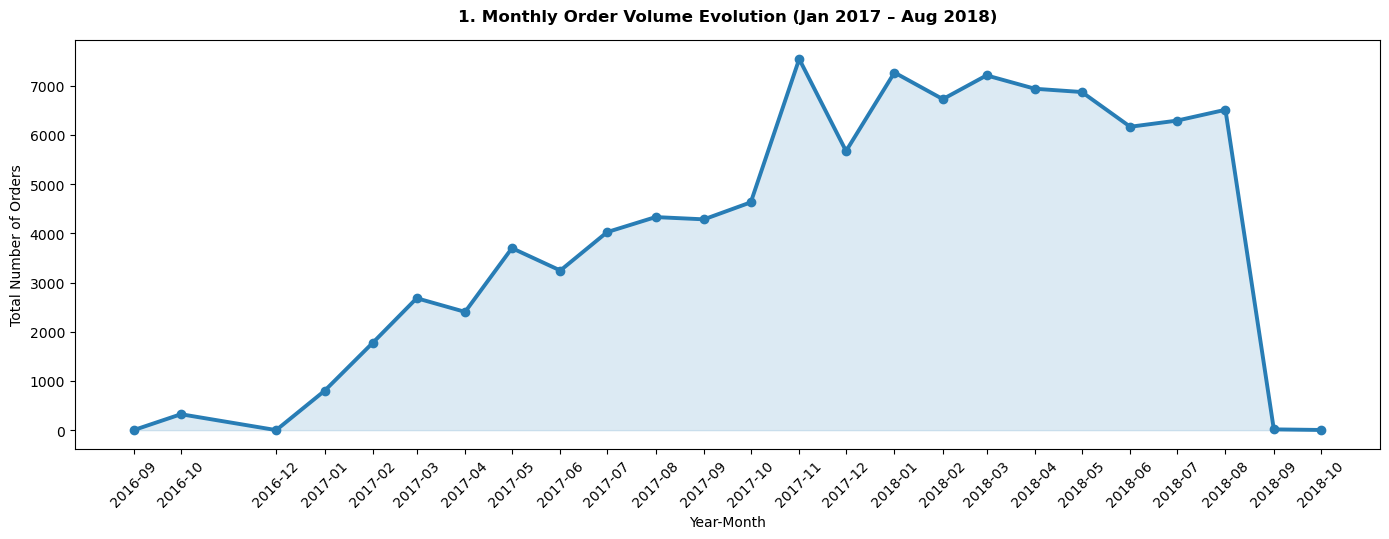

In [20]:
# Chart 1: Monthly order volume — calculate counts, then plot them with Matplotlib.
fig, ax = plt.subplots(figsize=(14, 5.5))
ax.plot(monthly_summary["purchase_month"], monthly_summary["order_count"],
        marker="o", linewidth=2.8, color="#287db5")
ax.fill_between(monthly_summary["purchase_month"], monthly_summary["order_count"],
                alpha=0.16, color="#287db5")
ax.set_title("1. Monthly Order Volume Evolution (Jan 2017 – Aug 2018)", pad=14)
ax.set_xlabel("Year-Month")
ax.set_ylabel("Total Number of Orders")
ax.grid(False)
ax.tick_params(axis="x", rotation=45)
ax.set_xticks(monthly_summary["purchase_month"])
ax.set_xticklabels(monthly_summary["purchase_month"].dt.strftime("%Y-%m"))
plt.tight_layout()
plt.show()

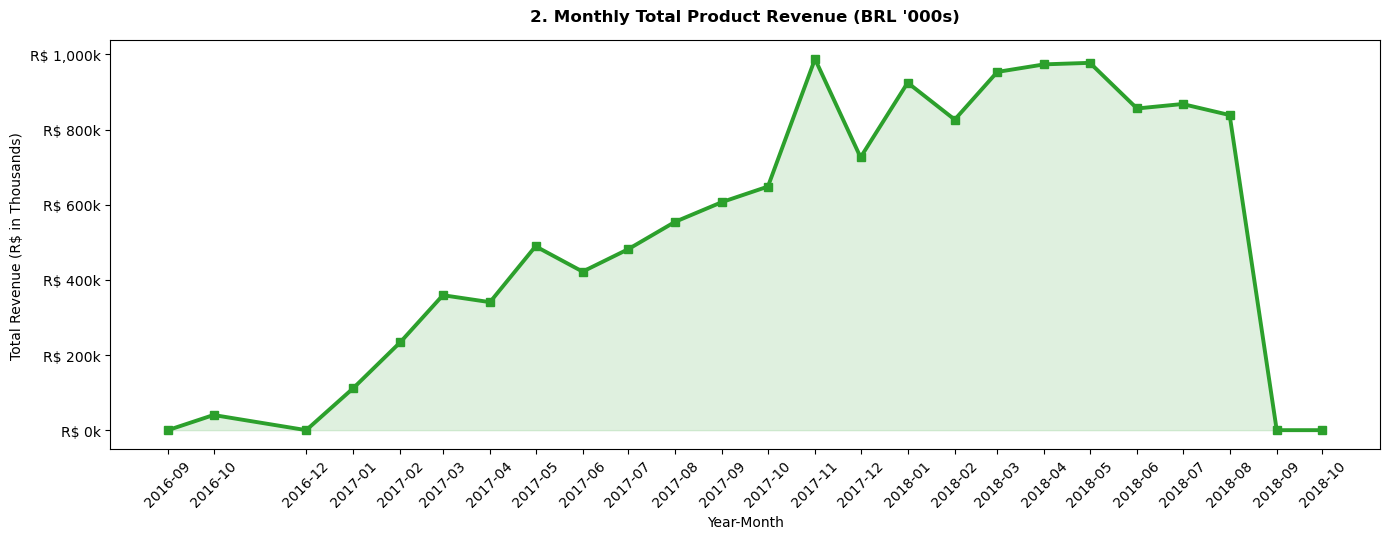

In [21]:
# Chart 2: Monthly delivered item revenue (GMV), grouped by purchase month.
# GMV = sum of item prices; it is not profit and excludes freight.
fig, ax = plt.subplots(figsize=(14, 5.5))
revenue_thousands = monthly_summary["delivered_item_gmv"] / 1000
ax.plot(monthly_summary["purchase_month"], revenue_thousands,
        marker="s", linewidth=2.8, color="#2ca02c")
ax.fill_between(monthly_summary["purchase_month"], revenue_thousands,
                alpha=0.15, color="#2ca02c")
ax.set_title("2. Monthly Total Product Revenue (BRL '000s)", pad=14)
ax.set_xlabel("Year-Month")
ax.set_ylabel("Total Revenue (R$ in Thousands)")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("R$ {x:,.0f}k"))
ax.set_xticks(monthly_summary["purchase_month"])
ax.set_xticklabels(monthly_summary["purchase_month"].dt.strftime("%Y-%m"), rotation=45)
plt.tight_layout()
plt.show()

### What you are learning from charts 1–2

- `groupby()` aggregates raw rows into monthly business metrics.
- `plot()` draws a line chart; `fill_between()` shades the area under it.
- The second chart divides BRL by 1,000 for readable labels.
- Interpret trends carefully: the first and last months may be partial, and delivered GMV is grouped by **purchase month**.


**Interpretation:** describe visible peaks, dips, and longer-term changes after running the charts. Check whether the first or last month is incomplete before comparing it with full months.

## 12. Product category analysis

We join products to their English category translation, then calculate the sum of item prices for items belonging to delivered orders. Missing category translations are labeled as unknown instead of silently removed.

In [22]:
products_with_category = products_clean.merge(
    translation_clean,
    on="product_category_name",
    how="left",
    validate="many_to_one",
)
products_with_category["category_clean"] = (
    products_with_category["product_category_name_english"]
    .fillna(products_with_category["product_category_name"])
    .fillna("unknown")
)

items_products = items_clean.merge(
    products_with_category[["product_id", "category_clean"]],
    on="product_id",
    how="left",
    validate="many_to_one",
)
delivered_order_ids = set(delivered["order_id"])
delivered_items = items_products[items_products["order_id"].isin(delivered_order_ids)].copy()

top_categories = (
    delivered_items.groupby("category_clean")["price"]
    .sum().sort_values(ascending=False).head(10).sort_values()
)
display(top_categories.sort_values(ascending=False).to_frame("delivered_item_gmv_brl"))

,delivered_item_gmv_brl
category_clean,
health_beauty,"1,233,131.72"
watches_gifts,"1,165,898.98"
bed_bath_table,"1,023,434.76"
sports_leisure,"954,673.55"
computers_accessories,"888,613.62"
furniture_decor,"711,927.69"
housewares,"615,628.69"
cool_stuff,"610,204.10"
auto,"578,849.35"


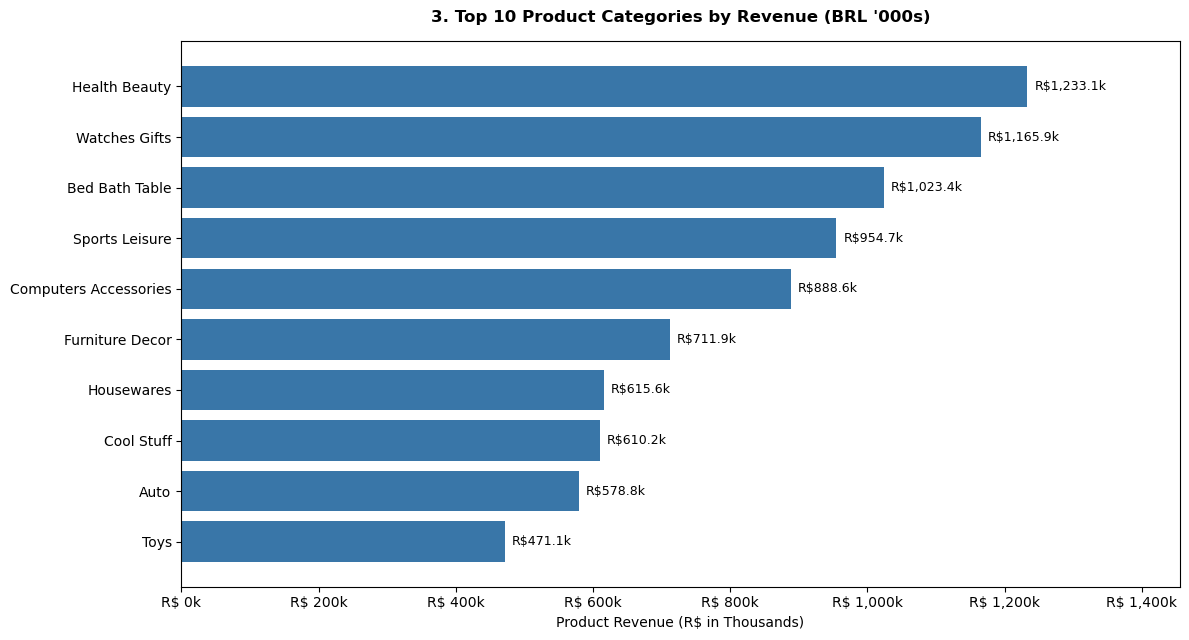

In [23]:
# Chart 3: Top 10 categories by delivered item revenue, with labels.
category_plot = top_categories.sort_values(ascending=True)
category_labels = category_plot.index.str.replace("_", " ").str.title()
category_thousands = category_plot.values / 1000
fig, ax = plt.subplots(figsize=(12, 6.5))
bars = ax.barh(category_labels, category_thousands, color="#3976a8")
ax.set_title("3. Top 10 Product Categories by Revenue (BRL '000s)", pad=14)
ax.set_xlabel("Product Revenue (R$ in Thousands)")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("R$ {x:,.0f}k"))
ax.bar_label(bars, labels=[f"R${v:,.1f}k" for v in category_thousands], padding=5, fontsize=9)
ax.set_xlim(0, max(category_thousands) * 1.18)
plt.tight_layout()
plt.show()

## 13. Geographic analysis

We compare states by delivered item GMV. This measures sales value in the dataset, not delivery quality or state-level profitability.

In [24]:
state_gmv = (
    delivered.dropna(subset=["customer_state"])
    .groupby("customer_state")["item_gmv"]
    .sum().sort_values(ascending=False).head(10).sort_values()
)
display(state_gmv.sort_values(ascending=False).to_frame("delivered_item_gmv_brl"))

,delivered_item_gmv_brl
customer_state,
SP,"5,066,562.98"
RJ,"1,759,651.13"
MG,"1,552,481.83"
RS,"728,718.47"
PR,"666,063.51"
SC,"507,012.13"
BA,"493,584.14"
DF,"296,498.41"
GO,"282,836.70"


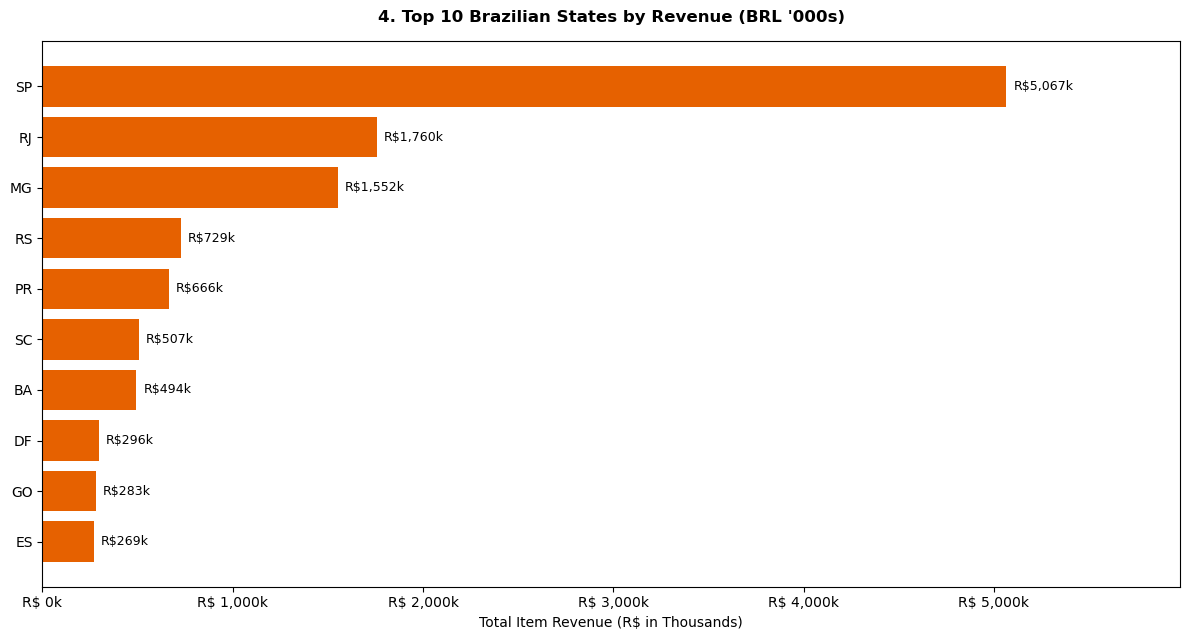

In [25]:
# Chart 4: Top 10 Brazilian states by delivered item revenue.
# This is a sales-value ranking, not a ranking of delivery quality.
state_plot = state_gmv.sort_values(ascending=True)
state_thousands = state_plot.values / 1000
fig, ax = plt.subplots(figsize=(12, 6.5))
bars = ax.barh(state_plot.index, state_thousands, color="#e66100")
ax.set_title("4. Top 10 Brazilian States by Revenue (BRL '000s)", pad=14)
ax.set_xlabel("Total Item Revenue (R$ in Thousands)")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("R$ {x:,.0f}k"))
ax.bar_label(bars, labels=[f"R${v:,.0f}k" for v in state_thousands], padding=5, fontsize=9)
ax.set_xlim(0, max(state_thousands) * 1.18)
plt.tight_layout()
plt.show()

## 14. Delivery performance

Delivery duration is calculated from purchase time to customer delivery. Punctuality is assessed only when both the actual delivery date and estimated delivery date are valid.

In [26]:
delivery = master.loc[
    master["order_status"].eq("delivered")
    & master["order_delivered_customer_date"].notna()
    & master["order_purchase_timestamp"].notna()
].copy()

delivery["delivery_days"] = (
    delivery["order_delivered_customer_date"] - delivery["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Negative durations are invalid and excluded from duration summaries.
valid_duration = delivery.loc[delivery["delivery_days"].ge(0)].copy()

valid_punctuality = delivery.dropna(
    subset=["order_delivered_customer_date", "order_estimated_delivery_date"]
).copy()
valid_punctuality["delivery_status"] = np.where(
    valid_punctuality["order_delivered_customer_date"]
    <= valid_punctuality["order_estimated_delivery_date"],
    "On time",
    "Late",
)

print("Delivered orders with valid duration:", len(valid_duration))
print("Delivered orders with valid actual and estimated dates:", len(valid_punctuality))
print("Missing estimated dates in delivered orders:", delivery["order_estimated_delivery_date"].isna().sum())

display(valid_duration["delivery_days"].describe().to_frame("delivery_days"))
display(valid_punctuality["delivery_status"].value_counts().to_frame("orders"))

Delivered orders with valid duration: 96470
Delivered orders with valid actual and estimated dates: 96470
Missing estimated dates in delivered orders: 0


,delivery_days
count,"96,470.00"
mean,12.56
std,9.55
min,0.53
25%,6.77
50%,10.22
75%,15.72
max,209.63


,orders
delivery_status,
On time,88644
Late,7826


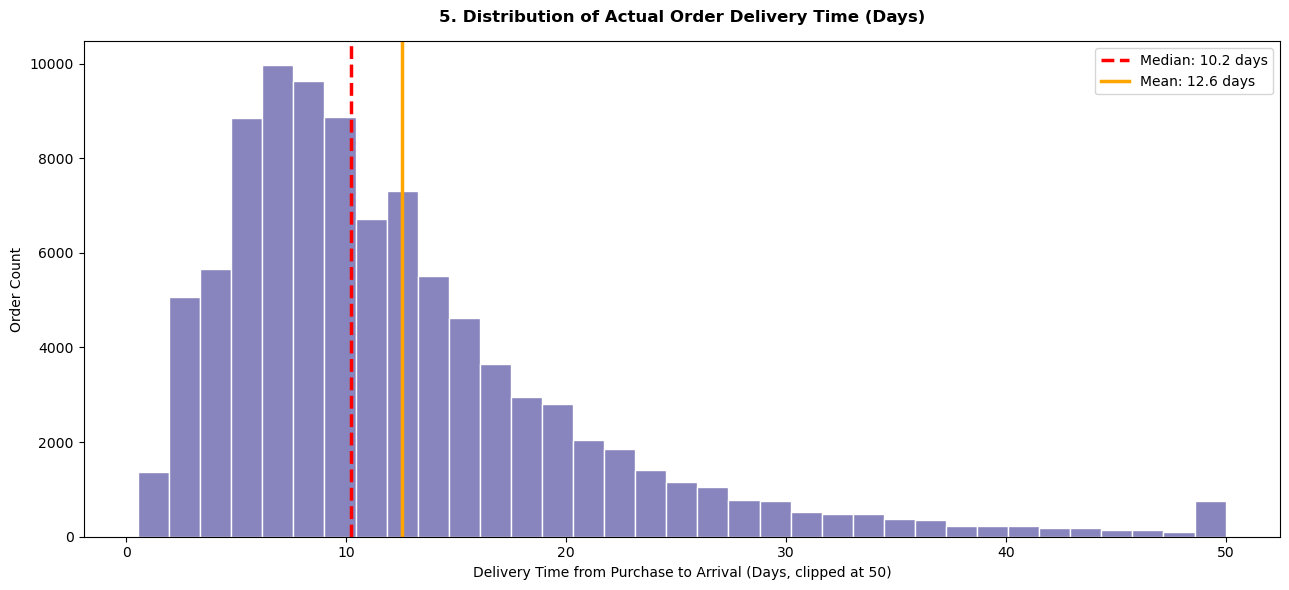

In [27]:
# Chart 5: Delivery-time distribution. Values above 50 days are clipped into the final bin
# only for display; mean and median are calculated from all valid non-negative durations.
delivery_days = valid_duration["delivery_days"].dropna()
if not delivery_days.empty:
    median_days = delivery_days.median()
    mean_days = delivery_days.mean()
    fig, ax = plt.subplots(figsize=(13, 6))
    ax.hist(delivery_days.clip(upper=50), bins=35, color="#8884bd", edgecolor="white")
    ax.axvline(median_days, color="red", linestyle="--", linewidth=2.5,
               label=f"Median: {median_days:.1f} days")
    ax.axvline(mean_days, color="orange", linewidth=2.5,
               label=f"Mean: {mean_days:.1f} days")
    ax.set_title("5. Distribution of Actual Order Delivery Time (Days)", pad=14)
    ax.set_xlabel("Delivery Time from Purchase to Arrival (Days, clipped at 50)")
    ax.set_ylabel("Order Count")
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("No valid delivery durations are available to plot.")

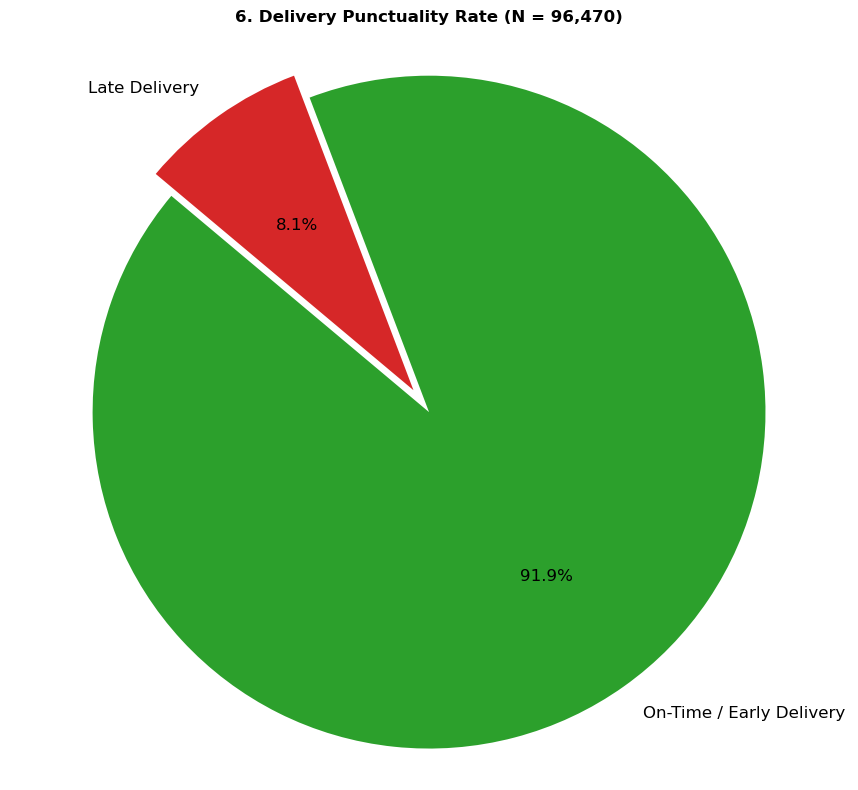

On-time/early: 91.9%
Late: 8.1%


In [28]:
# Chart 6: On-time vs late delivery share. Missing estimated dates are excluded above.
delivery_counts = valid_punctuality["delivery_status"].value_counts().reindex(
    ["On time", "Late"], fill_value=0
)
if delivery_counts.sum() > 0:
    colors = ["#2ca02c", "#d62728"]
    fig, ax = plt.subplots(figsize=(9, 8))
    ax.pie(delivery_counts.values, labels=["On-Time / Early Delivery", "Late Delivery"],
           autopct="%1.1f%%", startangle=140, explode=(0, 0.08),
           colors=colors, textprops={"fontsize": 12})
    ax.set_title(f"6. Delivery Punctuality Rate (N = {delivery_counts.sum():,})", pad=16)
    ax.axis("equal")
    plt.tight_layout()
    plt.show()
    delivery_percent = delivery_counts / delivery_counts.sum() * 100
    print(f"On-time/early: {delivery_percent['On time']:.1f}%")
    print(f"Late: {delivery_percent['Late']:.1f}%")
else:
    print("No orders have both actual and estimated delivery dates.")

## 15. Customer review analysis

Review scores are ordinal ratings from 1 to 5. We first inspect their distribution, then compare average review scores for orders with valid delivery dates that were on time or late. The comparison is descriptive and does not prove causation.

In [29]:
review_counts = reviews_clean["review_score"].value_counts(dropna=False).sort_index()
display(review_counts.to_frame("review_count"))

,review_count
review_score,
1,11424
2,3151
3,8179
4,19142
5,57328


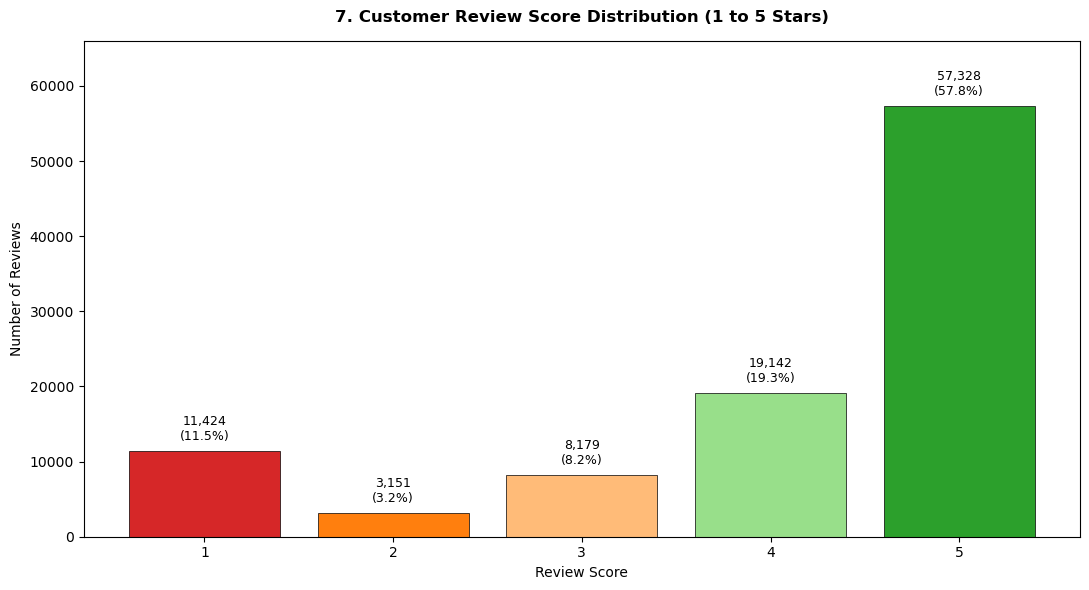

In [30]:
# Chart 7: Review score counts and percentages. Calculate labels from actual data.
scores = reviews_clean["review_score"].dropna()
review_counts = scores.astype(int).value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
review_percent = review_counts / review_counts.sum() * 100 if review_counts.sum() else review_counts.astype(float)
bar_colors = ["#d62728", "#ff7f0e", "#ffbb78", "#98df8a", "#2ca02c"]
fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.bar(review_counts.index.astype(str), review_counts.values,
              color=bar_colors, edgecolor="black", linewidth=0.5)
ax.set_title("7. Customer Review Score Distribution (1 to 5 Stars)", pad=14)
ax.set_xlabel("Review Score")
ax.set_ylabel("Number of Reviews")
for bar, count, pct in zip(bars, review_counts.values, review_percent.values):
    ax.annotate(f"{count:,}\n({pct:.1f}%)",
                (bar.get_x() + bar.get_width()/2, bar.get_height()),
                xytext=(0, 6), textcoords="offset points", ha="center", va="bottom", fontsize=9)
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

In [31]:
reviews_by_delivery = valid_punctuality.dropna(subset=["review_score"]).groupby(
    "delivery_status"
).agg(
    average_review_score=("review_score", "mean"),
    median_review_score=("review_score", "median"),
    order_count=("order_id", "nunique"),
).reindex(["On time", "Late"])

display(reviews_by_delivery)

,average_review_score,median_review_score,order_count
delivery_status,,,
On time,4.29,5.00,88163
Late,2.57,2.00,7661


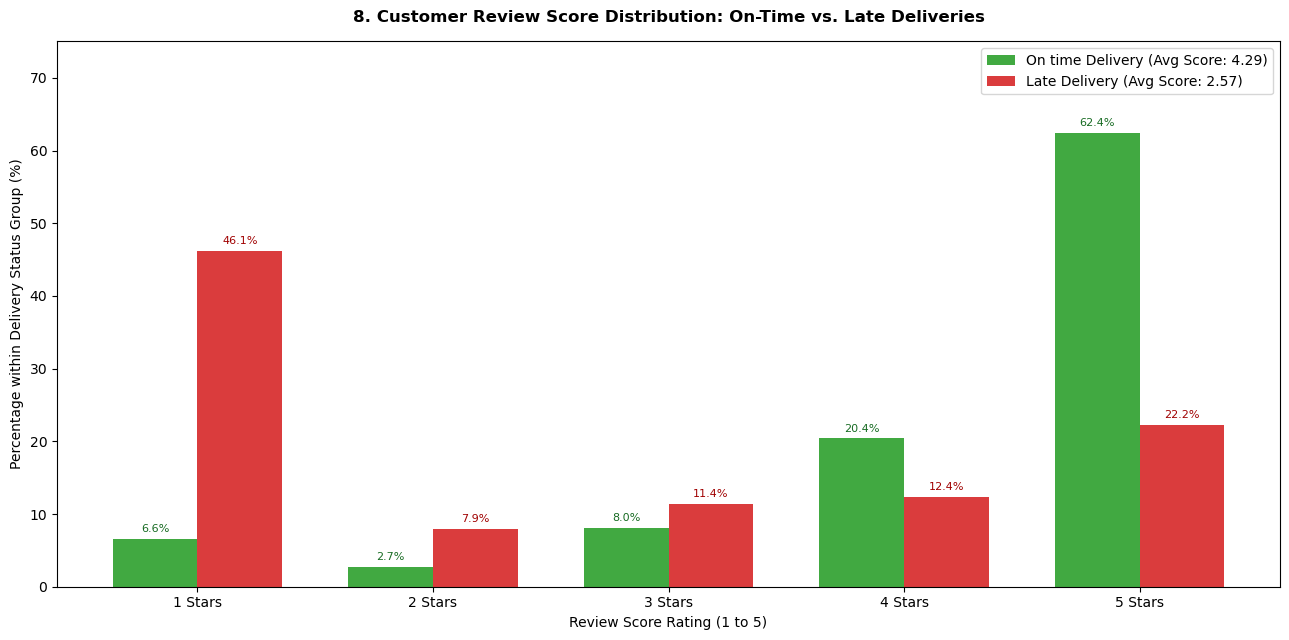

Average review score by delivery status:


,average_review_score
delivery_status,
On time,4.29
Late,2.57


In [32]:
# Chart 8: Compare the percentage distribution of review scores for on-time vs late orders.
# Average scores in the legend are computed dynamically, never typed as fixed values.
review_delivery = valid_punctuality.dropna(subset=["review_score"]).copy()
review_delivery["review_score"] = review_delivery["review_score"].astype(int)
score_order = [1, 2, 3, 4, 5]
score_labels = ["1 Stars", "2 Stars", "3 Stars", "4 Stars", "5 Stars"]
score_distribution = pd.crosstab(
    review_delivery["review_score"], review_delivery["delivery_status"], normalize="columns"
).reindex(score_order, fill_value=0) * 100
average_scores = review_delivery.groupby("delivery_status")["review_score"].mean()
status_order = ["On time", "Late"]
status_colors = {"On time": "#2ca02c", "Late": "#d62728"}

x = np.arange(len(score_order))
width = 0.36
fig, ax = plt.subplots(figsize=(13, 6.5))
for offset, status in zip([-width/2, width/2], status_order):
    values = score_distribution[status] if status in score_distribution.columns else pd.Series(0, index=score_order)
    bars = ax.bar(x + offset, values.values, width, color=status_colors[status],
                  alpha=0.9, label=f"{status} Delivery (Avg Score: {average_scores.get(status, float('nan')):.2f})")
    for bar, value in zip(bars, values.values):
        ax.annotate(f"{value:.1f}%", (bar.get_x() + bar.get_width()/2, bar.get_height()),
                    xytext=(0, 5), textcoords="offset points", ha="center", fontsize=8,
                    color="#176b22" if status == "On time" else "#a00000")
ax.set_xticks(x)
ax.set_xticklabels(score_labels)
ax.set_title("8. Customer Review Score Distribution: On-Time vs. Late Deliveries", pad=14)
ax.set_xlabel("Review Score Rating (1 to 5)")
ax.set_ylabel("Percentage within Delivery Status Group (%)")
ax.legend(loc="upper right")
ax.set_ylim(0, max(75, float(score_distribution.max().max()) * 1.18 if not score_distribution.empty else 75))
plt.tight_layout()
plt.show()

print("Average review score by delivery status:")
display(average_scores.reindex(status_order).rename("average_review_score").to_frame())

### What you are learning from charts 3–8

- Horizontal bar charts rank categories and states; labels are calculated from the aggregated values.
- A histogram shows the distribution of delivery times; the mean is sensitive to unusually long deliveries, while the median is more robust.
- The pie chart compares punctuality only for delivered orders with both actual and estimated delivery dates.
- The review chart shows how common each score is. The final grouped chart uses percentages **within each delivery group**, so group sizes do not distort the comparison.
- These are descriptive associations; they do not prove that a delivery delay alone caused a low review.


## 16. Explore the relationship between delays and reviews

We compare review score distributions across delivery groups. The percentages below are calculated within each group, making the groups easier to compare despite different sizes.

In [33]:
review_crosstab = pd.crosstab(
    valid_punctuality["delivery_status"],
    valid_punctuality["review_score"],
    normalize="index"
).mul(100).round(1)

display(review_crosstab)

review_score,1.00,1.50,2.00,2.50,3.00,3.33,3.50,4.00,4.33,4.50,5.00
delivery_status,,,,,,,,,,,
Late,46.10,0.00,7.90,0.10,11.30,0.00,0.00,12.30,0.00,0.00,22.20
On time,6.60,0.00,2.60,0.00,8.00,0.00,0.00,20.30,0.00,0.10,62.40


In [34]:
# Compare the proportion of 1-star reviews by delivery status.
one_star = valid_punctuality.assign(
    one_star=valid_punctuality["review_score"].eq(1)
).groupby("delivery_status")["one_star"].mean().mul(100)

display(one_star.rename("one_star_review_percent").to_frame())

,one_star_review_percent
delivery_status,
Late,45.14
On time,6.52


**How to interpret:** if late orders have lower average scores or a higher share of one-star reviews, this suggests an association in this dataset. Other factors may also influence reviews, so the result alone does not prove that delivery delay caused a low score.

## 17. Generate data-driven business insights

The statements below are generated from calculated results. They should be interpreted alongside sample sizes and data limitations.

In [35]:
print("BUSINESS INSIGHTS")
print("-" * 60)
print(f"Unique orders in the orders table: {total_orders:,}")
print(f"Delivered orders with a valid delivery date: {len(delivered):,}")
print(f"Delivered item GMV: R$ {delivered_gmv:,.2f}")

if not top_categories.empty:
    print(f"Highest-GMV product category: {top_categories.idxmax().replace('_', ' ').title()} "
          f"(R$ {top_categories.max():,.2f})")

if not state_gmv.empty:
    print(f"Highest-GMV customer state: {state_gmv.idxmax()} "
          f"(R$ {state_gmv.max():,.2f})")

if not valid_punctuality.empty:
    late_rate = valid_punctuality["delivery_status"].eq("Late").mean() * 100
    print(f"Late delivery rate among orders with valid dates: {late_rate:.2f}%")

if not reviews_by_delivery["average_review_score"].dropna().empty:
    print("\nAverage review score by delivery status:")
    print(reviews_by_delivery["average_review_score"].dropna().round(2).to_string())

BUSINESS INSIGHTS
------------------------------------------------------------
Unique orders in the orders table: 99,441
Delivered orders with a valid delivery date: 96,470
Delivered item GMV: R$ 13,220,248.93
Highest-GMV product category: Health Beauty (R$ 1,233,131.72)
Highest-GMV customer state: SP (R$ 5,066,562.98)
Late delivery rate among orders with valid dates: 8.11%

Average review score by delivery status:
delivery_status
On time   4.29
Late      2.57


### Turn findings into recommendations

Use the measured results to decide which recommendations are justified. For example:

- If one category contributes a large share of delivered item GMV, investigate whether it also has strong order volume and customer satisfaction before prioritizing it.
- If the late-delivery rate is high, investigate carriers, regions, and time periods before proposing operational changes.
- If late orders have worse reviews, examine other factors and sample sizes before concluding that delays explain dissatisfaction.

Do not make recommendations based on a chart alone when the analysis has not checked the relevant context.

## 18. Limitations and next steps

- **GMV is not profit:** item prices do not include product costs, operating expenses, or all financial adjustments.
- **Freight is separate:** the main delivered item GMV metric excludes freight charges.
- **Missing dates:** punctuality calculations only include orders with valid actual and estimated delivery dates.
- **Reviews are selective:** not every customer necessarily submits a review.
- **Association is not causation:** differences in review scores may have multiple explanations.
- **Time coverage:** incomplete first or last months can distort monthly comparisons.

Possible next steps are to investigate delivery performance by state, compare review patterns across product categories, and analyze freight separately.

## 19. Final conclusion

After running the notebook, summarize the most important verified findings here. Use the actual numbers and charts produced above; do not insert guessed statistics.

A strong final conclusion answers:
1. What changed over time?
2. Which categories or states contributed the most delivered item GMV?
3. What did the delivery analysis reveal?
4. How did review scores differ across delivery groups?
5. What would you investigate next?

### Skills demonstrated
Python fundamentals, data loading, data quality checks, cleaning, NumPy calculations, Pandas filtering and aggregation, safe table merging, KPI definitions, Matplotlib visualization, and business interpretation.